# Nauka 01 – od ramek do mapy gęstości

**Czego się nauczysz:**
1. jak z ramek `[x, y, w, h]` zrobić **punkty** (środki kłosów),
2. czym jest **mapa gęstości** – na małym, sztucznym przykładzie 9×9,
3. co się dzieje z kłosem **przy krawędzi obrazu** i jak to naprawić,
4. jak zbudować mapę dla prawdziwego obrazu i **sprawdzić, że jej suma = liczba kłosów**.

**Główna idea:** model mapy gęstości nie rysuje ramek. Uczy się przewidywać obrazek „ciepła”,
w którym każdy kłos to mała plama o łącznej „masie” równej 1. Liczba kłosów = **suma** całej mapy.

Tu nie ma jeszcze modelu ani PyTorch – tylko NumPy, żeby zrozumieć, co model będzie miał przewidywać.

## Krok 1. Wczytanie jednego obrazu i jego ramek

**Co robi kod:** wczytuje plik walidacyjny, bierze jeden wiersz i zamienia ramki na tablicę NumPy
o kształcie `(N, 4)` – `N` ramek, każda po 4 liczby `[x, y, w, h]`.

**Dlaczego `reshape(-1, 4)`:** obraz bez kłosów ma pustą listę ramek. Bez `reshape` dostalibyśmy
tablicę o kształcie `(0,)` zamiast `(0, 4)` i dalsze obliczenia by się wywróciły.
`-1` znaczy „policz sama, ile ma być wierszy”.

**Co zobaczysz:** rozmiar obrazu `(1024, 1024)`, kształt tablicy ramek np. `(43, 4)` i jej typ `float32`.

**Jak sprawdzić:** komórka kończy się asercjami (`assert`). Jeśli coś się nie zgadza,
dostaniesz `AssertionError` z opisem – brak błędu oznacza, że wszystko OK.

**Typowe błędy:** `FileNotFoundError` – zła ścieżka (notebook musi leżeć w `notebooks/`);
`ImportError: pyarrow` – wybrany zły kernel (wybierz `.venv`).

Obraz (szer., wys.): (1024, 1024)
Kształt tablicy ramek: (14, 4) | typ: float32
Pierwsze 3 ramki [x, y, w, h]:
 [[756. 850. 174. 174.]
 [252. 138.  82.  69.]
 [960. 157.  64.  88.]]


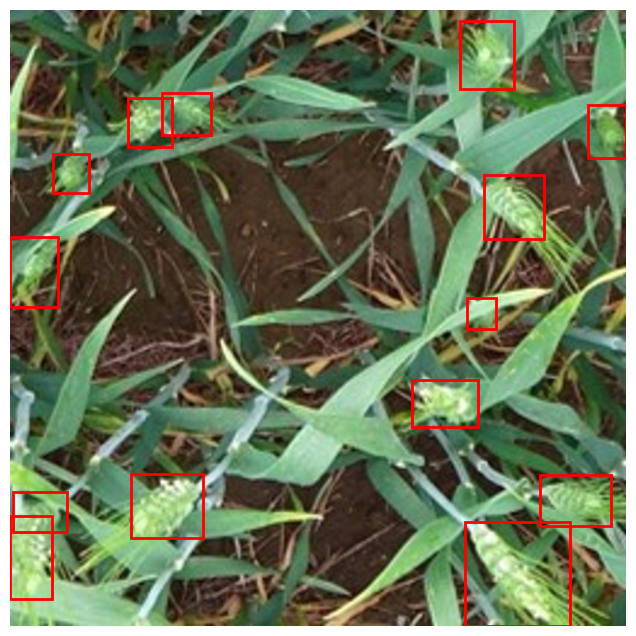

In [1]:
import io
from pathlib import Path

import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PARQUET = ROOT / "data" / "raw" / "gwhd_hf" / "validation-00000-of-00001.parquet"

df = pd.read_parquet(PARQUET)

ROW_INDEX = 0  # <- zmień, żeby obejrzeć inny obraz
row = df.iloc[ROW_INDEX]

img = Image.open(io.BytesIO(row["image"]["bytes"])).convert("RGB")
W, H = img.size  # PIL podaje (szerokość, wysokość)

boxes = np.array(list(row["objects"]["boxes"]), dtype=np.float32).reshape(-1, 4)

print("Obraz (szer., wys.):", (W, H))
print("Kształt tablicy ramek:", boxes.shape, "| typ:", boxes.dtype)
print("Pierwsze 3 ramki [x, y, w, h]:\n", boxes[:3])

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

for x, y, w, h in boxes:
    prostokat = Rectangle(
        (x, y), w, h,
        linewidth=2,
        edgecolor="red",
        facecolor="none"
    )
    ax.add_patch(prostokat)

ax.axis("off")
plt.show()

# Kontrole: czy dane wyglądają tak, jak zakładamy?
assert boxes.ndim == 2 and boxes.shape[1] == 4, "ramki powinny mieć kształt (N, 4)"
assert (boxes[:, 2] >= 0).all() and (boxes[:, 3] >= 0).all(), "szerokość/wysokość nie może być ujemna"
assert (boxes[:, 0] + boxes[:, 2] <= W).all() and (boxes[:, 1] + boxes[:, 3] <= H).all(), "ramka wychodzi poza obraz"


## Krok 2. Środki ramek = punkty

**Co robi kod:** dla każdej ramki liczy środek:
`cx = x + w/2`, `cy = y + h/2`. To jest **założenie**: że środek ramki to dobre miejsce na „kropkę” kłosa.
Dla kłosów przyciętych krawędzią obrazu środek ramki nie jest środkiem całego kłosa – ale leży na widocznej części.

**NumPy bez pętli:** `boxes[:, 0]` to „kolumna 0 ze wszystkich wierszy”, czyli wszystkie `x` naraz.
Działania na całych kolumnach są szybkie i czytelne.

**Co zobaczysz:** tablicę `points` o kształcie `(N, 2)` i obraz z ramkami oraz żółtymi kropkami w środkach.

**Jak sprawdzić:** liczba punktów = liczba ramek; każda kropka leży w swojej ramce (oceń wzrokiem).

**Typowe błędy:** pomylenie osi – `x` to kolumna (poziomo), `y` to wiersz (pionowo).
W tablicach NumPy indeksujemy `[wiersz, kolumna]`, czyli `[y, x]` – odwrotnie niż przy rysowaniu!

Kształt points: (14, 2)
Pierwsze 3 punkty [cx, cy]:
 [[843.  937. ]
 [293.  172.5]
 [992.  201. ]]


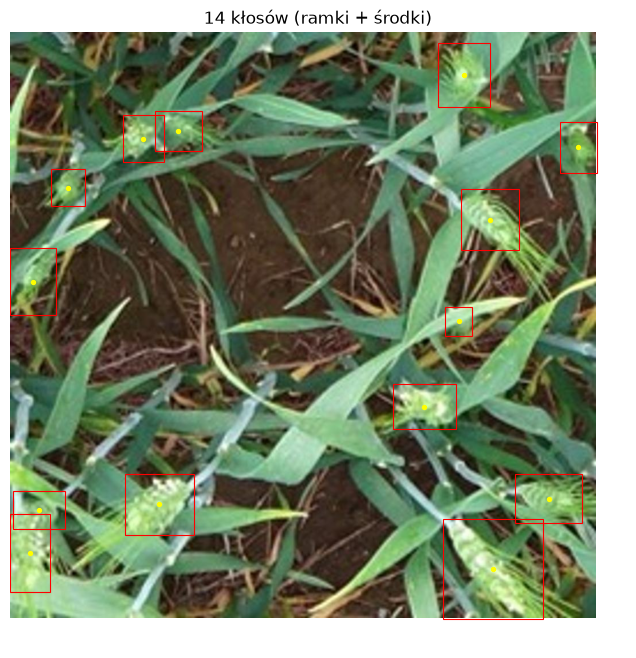

In [2]:
cx = boxes[:, 0] + boxes[:, 2] / 2
cy = boxes[:, 1] + boxes[:, 3] / 2
points = np.stack([cx, cy], axis=1)  # kształt (N, 2): kolumny [x, y]

print("Kształt points:", points.shape)
print("Pierwsze 3 punkty [cx, cy]:\n", points[:3])

assert len(points) == len(boxes)
assert ((points[:, 0] >= 0) & (points[:, 0] <= W) & (points[:, 1] >= 0) & (points[:, 1] <= H)).all()

fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(img)
for x, y, w, h in boxes:
    ax.add_patch(Rectangle((x, y), w, h, fill=False, edgecolor="red", linewidth=0.8))
ax.scatter(points[:, 0], points[:, 1], s=8, c="yellow")
ax.set_title(f"{len(points)} kłosów (ramki + środki)")
ax.axis("off")
plt.show()

## Krok 3. Mapa gęstości na małym przykładzie (9×9)

Zanim weźmiemy obraz 1024×1024, zobaczmy ideę na malutkiej siatce **9×9**, którą da się wypisać w całości.

**Najprostsza mapa:** same zera i **jedynka** w pikselu, gdzie jest kłos. Suma = 1 = liczba kłosów.
Problem: dla sieci neuronowej trafienie dokładnie w jeden piksel jest bardzo trudne.

**Rozmycie Gaussa:** zamiast jedynki w jednym pikselu, „rozsmarowujemy” ją na sąsiednie piksele
w kształcie dzwonu (rozkład Gaussa). Kluczowe: **normalizujemy jądro, żeby jego suma = 1**.
Wtedy kłos nadal „waży” dokładnie 1, tylko jest rozmyty.

- *Jądro (kernel)* – mała tablica z kształtem dzwonu, którą „przykładamy” w miejscu kłosa.
- *sigma* – szerokość dzwonu w pikselach. Większa sigma = szersza, niższa plama.
- *Promień* – jądro ucinamy na `3·sigma` od środka; dalej wartości są praktycznie zerowe.

**Co zobaczysz:** wypisane liczby jądra, jego sumę `1.0` i mapę 9×9 z plamą w środku.

**Typowe błędy:** brak normalizacji – suma jądra wychodzi np. 6.28 zamiast 1 i model „liczy” 6 razy za dużo.

Kształt jądra: (7, 7)
[[0.    0.    0.001 0.002 0.001 0.    0.   ]
 [0.    0.003 0.013 0.022 0.013 0.003 0.   ]
 [0.001 0.013 0.059 0.097 0.059 0.013 0.001]
 [0.002 0.022 0.097 0.159 0.097 0.022 0.002]
 [0.001 0.013 0.059 0.097 0.059 0.013 0.001]
 [0.    0.003 0.013 0.022 0.013 0.003 0.   ]
 [0.    0.    0.001 0.002 0.001 0.    0.   ]]
Suma jądra: 1.0

Suma mapy 9x9 (powinna być 1): 1.0


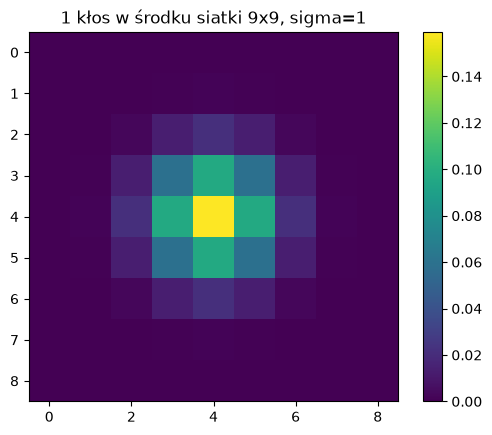

In [3]:
def gaussian_kernel(sigma: float) -> np.ndarray:
    """Kwadratowe jądro Gaussa o boku 2*promień+1, znormalizowane do sumy 1."""
    radius = int(np.ceil(3 * sigma))
    ax = np.arange(-radius, radius + 1)          # np. [-3, -2, -1, 0, 1, 2, 3]
    g = np.exp(-(ax ** 2) / (2 * sigma ** 2))    # dzwon w 1D
    kernel = np.outer(g, g)                      # dzwon w 2D (iloczyn zewnętrzny)
    return (kernel / kernel.sum()).astype(np.float32)


k = gaussian_kernel(sigma=1.0)
np.set_printoptions(precision=3, suppress=True)
print("Kształt jądra:", k.shape)
print(k)
print("Suma jądra:", k.sum())
assert abs(k.sum() - 1) < 1e-5

# Wklejamy jądro w środek pustej siatki 9x9
small = np.zeros((9, 9), dtype=np.float32)
r = k.shape[0] // 2
small[4 - r:4 + r + 1, 4 - r:4 + r + 1] += k
print("\nSuma mapy 9x9 (powinna być 1):", small.sum())

plt.imshow(small, cmap="viridis")
plt.colorbar()
plt.title("1 kłos w środku siatki 9x9, sigma=1")
plt.show()

## Krok 4. Przypadek brzegowy: kłos przy krawędzi

**Co robi kod:** stawia kłos w rogu siatki `(0, 0)`. Połowa jądra „wystaje” poza siatkę, więc ją ucinamy.
Wtedy suma mapy spada poniżej 1 – **zgubiliśmy część kłosa**. Na prawdziwych obrazach kłosów
przy krawędziach jest sporo, więc model nauczyłby się systematycznie zaniżać wynik.

**Naprawa:** po ucięciu jądra normalizujemy **ucięty kawałek** ponownie do sumy 1.

**Co zobaczysz:** dwie liczby – suma ok. 0.5 bez naprawy (zostaje tylko ćwiartka jądra plus jego środkowy wiersz i kolumna) i dokładnie 1 z naprawą.

**Jak sprawdzić:** asercja na końcu komórki.

**Typowe błędy:** ujemne indeksy – w Pythonie `tablica[-2:]` oznacza „dwa ostatnie elementy”, a nie
„od minus dwóch”. Dlatego granice jądra trzeba jawnie przyciąć do zakresu `0 … rozmiar`.

In [4]:
def add_point(density: np.ndarray, x: float, y: float, kernel: np.ndarray, renormalize: bool = True) -> None:
    """Dodaje jeden kłos (jądro Gaussa) do mapy w miejscu (x, y). Zmienia `density` w miejscu."""
    h, w = density.shape
    r = kernel.shape[0] // 2
    # piksel, w którym leży punkt; min(...) chroni przed x == w (punkt dokładnie na prawej krawędzi)
    col = min(int(x), w - 1)
    row = min(int(y), h - 1)

    # zakres na mapie (przycięty do granic obrazu)
    top, bottom = max(row - r, 0), min(row + r + 1, h)
    left, right = max(col - r, 0), min(col + r + 1, w)
    # odpowiadający mu kawałek jądra
    piece = kernel[top - (row - r):bottom - (row - r), left - (col - r):right - (col - r)]

    if renormalize:
        piece = piece / piece.sum()
    density[top:bottom, left:right] += piece


k = gaussian_kernel(sigma=1.0)

corner_bad = np.zeros((9, 9), dtype=np.float32)
add_point(corner_bad, 0, 0, k, renormalize=False)
corner_ok = np.zeros((9, 9), dtype=np.float32)
add_point(corner_ok, 0, 0, k, renormalize=True)

print("Kłos w rogu, BEZ ponownej normalizacji, suma:", round(float(corner_bad.sum()), 4))
print("Kłos w rogu, Z ponowną normalizacją, suma:   ", round(float(corner_ok.sum()), 4))
assert abs(corner_ok.sum() - 1) < 1e-5

Kłos w rogu, BEZ ponownej normalizacji, suma: 0.4893
Kłos w rogu, Z ponowną normalizacją, suma:    1.0


## Krok 5. Mapa gęstości dla prawdziwego obrazu

**Co robi kod:** tworzy pustą mapę o rozmiarze obrazu `(H, W)` = `(1024, 1024)` i dodaje jądro
w każdym punkcie z kroku 2.

**sigma = hipoteza.** Na razie bierzemy stałą `SIGMA = 10` pikseli. Kłosy mają zwykle kilkadziesiąt
pikseli, więc plama jest mniejsza od kłosa. Jaka sigma jest najlepsza – to pytanie do eksperymentu,
nie pewnik. Spróbuj zmienić na 4 i 25 i porównaj wygląd.

**Co zobaczysz:** dwie liczby – liczbę kłosów i sumę mapy – prawie identyczne, oraz mapę obok obrazu.

**Jak sprawdzić:** asercja `|suma − N| < 0.01`. Drobna różnica (rzędu 0.0001) to błąd zaokrągleń
liczb `float32`, nie błąd w logice.

**Typowe błędy:** pomylenie kolejności `(W, H)` z PIL i `(H, W)` w NumPy. Przy obrazie
kwadratowym tego nie widać – i to właśnie dlatego jest groźne.

Kształt mapy (wys., szer.): (1024, 1024) | typ: float32
Liczba kłosów (ramek): 14
Suma mapy:             14.0


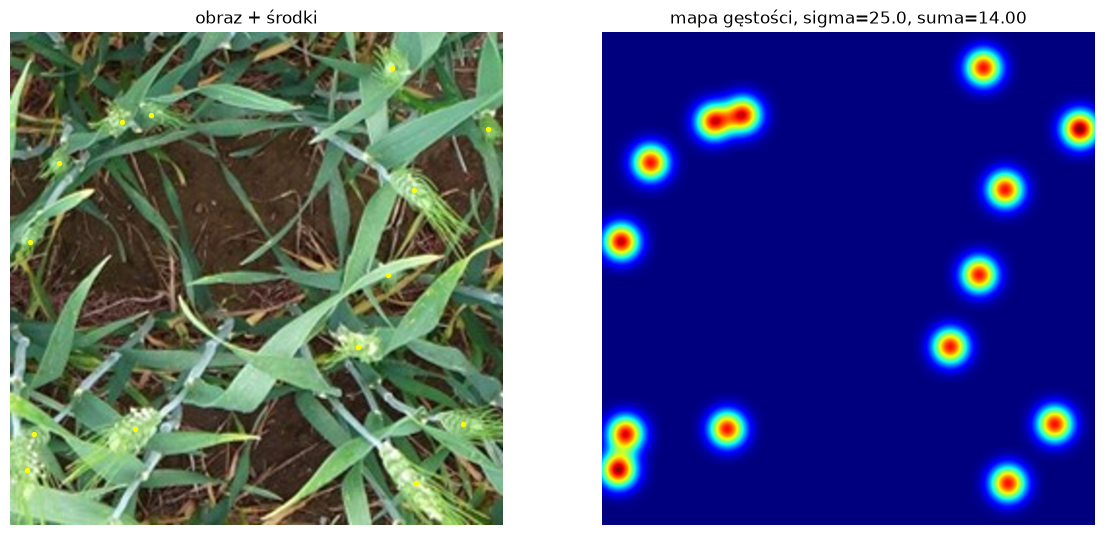

In [7]:
SIGMA = 25.0  # <- hipoteza; spróbuj 4 i 25

def density_map(points: np.ndarray, height: int, width: int, sigma: float) -> np.ndarray:
    """Mapa gęstości (height, width): każdy punkt [x, y] wnosi dokładnie 1."""
    density = np.zeros((height, width), dtype=np.float32)
    kernel = gaussian_kernel(sigma)
    for x, y in points:
        add_point(density, x, y, kernel)
    return density


dmap = density_map(points, H, W, SIGMA)

print("Kształt mapy (wys., szer.):", dmap.shape, "| typ:", dmap.dtype)
print("Liczba kłosów (ramek):", len(points))
print("Suma mapy:            ", round(float(dmap.sum()), 4))
assert dmap.shape == (H, W)
assert abs(dmap.sum() - len(points)) < 1e-2, "suma mapy nie zgadza się z liczbą kłosów!"

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
axes[0].imshow(img)
axes[0].scatter(points[:, 0], points[:, 1], s=8, c="yellow")
axes[0].set_title("obraz + środki")
axes[1].imshow(dmap, cmap="jet")
axes[1].set_title(f"mapa gęstości, sigma={SIGMA}, suma={dmap.sum():.2f}")
for a in axes:
    a.axis("off")
plt.show()

## Krok 6. Przypadek brzegowy: obraz bez kłosów

**Co robi kod:** szuka w zbiorze obrazu z pustą listą ramek i buduje dla niego mapę.

**Co zobaczysz:** kształt punktów `(0, 2)`, mapę z samych zer i sumę `0.0`.

**Dlaczego to ważne:** takie obrazy też trafią do treningu – model musi umieć powiedzieć „0”.
Kod nie może się na nich wywracać.

In [8]:
n_boxes = df["objects"].apply(lambda o: len(o["boxes"]))
empty_idx = int(np.flatnonzero(n_boxes.to_numpy() == 0)[0])
print("Obrazów bez kłosów w walidacji:", int((n_boxes == 0).sum()), "| biorę wiersz", empty_idx)

empty_boxes = np.array(list(df.iloc[empty_idx]["objects"]["boxes"]), dtype=np.float32).reshape(-1, 4)
empty_points = np.stack([empty_boxes[:, 0] + empty_boxes[:, 2] / 2,
                         empty_boxes[:, 1] + empty_boxes[:, 3] / 2], axis=1)
empty_map = density_map(empty_points, H, W, SIGMA)

print("Kształt punktów:", empty_points.shape, "| suma mapy:", float(empty_map.sum()))
assert empty_map.sum() == 0

Obrazów bez kłosów w walidacji: 28 | biorę wiersz 106
Kształt punktów: (0, 2) | suma mapy: 0.0


## Krok 7. Kontrola na wielu obrazach

**Co robi kod:** powtarza budowę mapy dla pierwszych 20 obrazów i porównuje sumę z liczbą kłosów.

**Co zobaczysz:** tabelkę `liczba kłosów | suma mapy | różnica`. Różnice powinny być bliskie zera.

**Jak sprawdzić:** asercja na największej różnicy.

In [9]:
rows = []
for i in range(20):
    b = np.array(list(df.iloc[i]["objects"]["boxes"]), dtype=np.float32).reshape(-1, 4)
    p = np.stack([b[:, 0] + b[:, 2] / 2, b[:, 1] + b[:, 3] / 2], axis=1)
    m = density_map(p, H, W, SIGMA)
    rows.append({"wiersz": i, "klosy": len(p), "suma_mapy": float(m.sum())})

check = pd.DataFrame(rows)
check["roznica"] = (check["suma_mapy"] - check["klosy"]).abs()
print(check.to_string(index=False))
print("\nNajwiększa różnica:", check["roznica"].max())
assert check["roznica"].max() < 1e-2

 wiersz  klosy  suma_mapy      roznica
      0     14  14.000000 0.000000e+00
      1     25  25.000000 0.000000e+00
      2      8   8.000000 4.768372e-07
      3     46  46.000000 0.000000e+00
      4     25  25.000000 0.000000e+00
      5     14  14.000000 0.000000e+00
      6     14  14.000000 0.000000e+00
      7     27  27.000000 0.000000e+00
      8     11  11.000000 0.000000e+00
      9     34  34.000000 0.000000e+00
     10     16  15.999999 9.536743e-07
     11     24  24.000000 0.000000e+00
     12     26  26.000000 0.000000e+00
     13     35  35.000000 0.000000e+00
     14     32  32.000000 0.000000e+00
     15     21  21.000000 0.000000e+00
     16     41  41.000000 0.000000e+00
     17     43  43.000000 0.000000e+00
     18     26  26.000000 0.000000e+00
     19     21  21.000000 0.000000e+00

Największa różnica: 9.5367431640625e-07


## Podsumowanie

**Co działa (sprawdzone asercjami):**
- ramki `[x, y, w, h]` → środki → mapa gęstości o rozmiarze obrazu,
- suma mapy = liczba kłosów, także dla kłosów przy krawędzi i dla obrazów bez kłosów.

**Co nadal jest hipotezą:**
- **środek ramki** jako położenie kłosa,
- **stała sigma = 10 px** – można też dobierać sigmę osobno do każdego kłosa, np. z rozmiaru ramki,
- **ponowna normalizacja przy krawędzi** – alternatywa to pozwolić, by kłos częściowo poza obrazem
  liczył się jako ułamek. Wybór trzeba opisać w pracy.

**Następny mały krok:** modele takie jak CSRNet zwracają mapę **8 razy mniejszą** niż obraz
(128×128 zamiast 1024×1024). Nauczymy się zmniejszać mapę tak, żeby **suma się nie zmieniła**.